# 1. Import Libraries

In [9]:

import torch
import torchvision

# Accessing project root
from pathlib import Path
import sys

# Root directory of Deep_Learning
ROOT_DIR = Path.cwd().parent
sys.path.append(str(ROOT_DIR))

# Import scripts from modular directory
from M02_Modularity.going_modular import data_setup, engine, model_builder, utils, evaluation

# 2. Set-Up data
 - device agnostic code.

In [10]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

Using device: cpu


In [11]:
# Define data directories
data_dir = ROOT_DIR / "Dataset/pizza_steak_sushi"
train_dir = data_dir / "train"
test_dir = data_dir / "test"
print(data_dir.exists(), train_dir.exists(), test_dir.exists())

True True True


In [12]:
from script import preprocess

train_transform, test_transform = preprocess()
train_dataloader, test_dataloader, class_names = data_setup.create_dataloaders(train_dir=train_dir,
                                                                                test_dir=test_dir,
                                                                                train_transform=train_transform,
                                                                                test_transform=test_transform,
                                                                                num_workers=4,
                                                                                batch_size=32)     

In [13]:

# for the torchvision which version of greater than 0.13 are added it auto transform module
# after the selecting the model we have installed the pretrained model weight.
# torchvision.models.weights.model_name_weights.defualt   (model_name.weights is the model architecture weights) and the last thing is default is select the best weights for our selected model artchitecture.
# so if i we know the best model version then we can call directly, if not default the best and esiast option

#  for example
weights = torchvision.models.ResNet18_Weights.DEFAULT
# print(weights)   # Then IMAGENET1K_V1 is the best weights for ResNet18 architecture. 


# Now i have to ask the model to give the data transform to train this type of model architecture.
auto_transform = weights.transforms()
print(f"The auto transform for ResNet18 is :\n {auto_transform}")

# The only problem when we using outo transform is lack of custom transformation like data augmentation.

The auto transform for ResNet18 is :
 ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


# 3. Geting Pre-Trained Model

### efficientnet_b0 architecture

<span style="color:red">Efficientnet_b0</span> - architecture is the baseline arhictecture of efficientnet families. it is developed by google developers in 2019. it focus on accuracy and computational efficiency. it's architecture is based on a series of convolutional layers designed to be lightweight and fast. it is best for users when their computational resource is limitted.  
Specifically for this model architecture:
- it expectes input resolution of 224 by 224 pixels
- it have approximat layer 237 layers
- it have learning parameters of around 5.6 milion
- accuracy is 77.1%

In [14]:
# Better performace model may be needs more computational power or needs good device.
# Understanding performace, speed and size of the model for any architecture of the model is important

# effficientnet_bx x- is variable may the balue differes.
# for now i'm using efficientnet_b0 architecture and the best weight for this architecture is efficientnet_b0_weights.IMAGENET1K_V1

# Then pretrained model that i use for this problem is efficientnet_b0_weights.

weights = torchvision.models.EfficientNet_B0_Weights.DEFAULT
print(weights)

# Then the model will be
model = torchvision.models.efficientnet_b0(weights = weights).to(device)
print(model)

EfficientNet_B0_Weights.IMAGENET1K_V1


EfficientNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (1): Sequential(
      (0): MBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
            (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (2): SiLU(inplace=True)
          )
          (1): SqueezeExcitation(
            (avgpool): AdaptiveAvgPool2d(output_size=1)
            (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
            (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
            (activation): SiLU(inplace=True)
            (scale_activation): Sigmoid()
          )
          (2): Conv2dNormActivat

In [15]:
from torchinfo import summary

# Print a summary using torchinfo (uncomment for actual output)
summary(model=model, 
        input_size=(32, 3, 224, 224), # make sure this is "input_size", not "input_shape"
        # col_names=["input_size"], # uncomment for smaller output
        col_names=["input_size", "output_size", "num_params", "trainable"],
        col_width=20,
        row_settings=["var_names"]
) 

Layer (type (var_name))                                      Input Shape          Output Shape         Param #              Trainable
EfficientNet (EfficientNet)                                  [32, 3, 224, 224]    [32, 1000]           --                   True
├─Sequential (features)                                      [32, 3, 224, 224]    [32, 1280, 7, 7]     --                   True
│    └─Conv2dNormActivation (0)                              [32, 3, 224, 224]    [32, 32, 112, 112]   --                   True
│    │    └─Conv2d (0)                                       [32, 3, 224, 224]    [32, 32, 112, 112]   864                  True
│    │    └─BatchNorm2d (1)                                  [32, 32, 112, 112]   [32, 32, 112, 112]   64                   True
│    │    └─SiLU (2)                                         [32, 32, 112, 112]   [32, 32, 112, 112]   --                   --
│    └─Sequential (1)                                        [32, 32, 112, 112]   [32, 16, 112

In [16]:
# train use pretrained model the feature extractor should not be trainable, so it must be frozen only classifier trainable. to do that requires_drad = false. gradient should not be track the the update.
for param in model.features.parameters():
    param.requires_grad = False

# Set the manual seeds
torch.manual_seed(42)
torch.cuda.manual_seed(42)

# Get the length of class_names (one output unit for each class)
output_shape = len(class_names)

# Recreate the classifier layer and seed it to the target device
model.classifier = torch.nn.Sequential(
    torch.nn.Dropout(p=0.2, inplace=True), 
    torch.nn.Linear(in_features=1280, 
                    out_features=output_shape, # same number of output units as our number of classes
                    bias=True)).to(device)

# # Do a summary *after* freezing the features and changing the output classifier layer (uncomment for actual output)
summary(model, 
        input_size=(32, 3, 224, 224), # make sure this is "input_size", not "input_shape" (batch_size, color_channels, height, width)
        verbose=0,
        col_names=["input_size", "output_size", "num_params", "trainable"],
        col_width=20,
        row_settings=["var_names"]
)

Layer (type (var_name))                                      Input Shape          Output Shape         Param #              Trainable
EfficientNet (EfficientNet)                                  [32, 3, 224, 224]    [32, 3]              --                   Partial
├─Sequential (features)                                      [32, 3, 224, 224]    [32, 1280, 7, 7]     --                   False
│    └─Conv2dNormActivation (0)                              [32, 3, 224, 224]    [32, 32, 112, 112]   --                   False
│    │    └─Conv2d (0)                                       [32, 3, 224, 224]    [32, 32, 112, 112]   (864)                False
│    │    └─BatchNorm2d (1)                                  [32, 32, 112, 112]   [32, 32, 112, 112]   (64)                 False
│    │    └─SiLU (2)                                         [32, 32, 112, 112]   [32, 32, 112, 112]   --                   --
│    └─Sequential (1)                                        [32, 32, 112, 112]   [32, 

In [17]:
from torch import nn
# Define loss and optimizer
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [18]:
# Set the random seeds
torch.manual_seed(42)
torch.cuda.manual_seed(42)

# Start the timer
from timeit import default_timer as timer 
start_time = timer()

# Setup training and save the results
results = engine.train_loop(model=model,
                       train_dataloader=train_dataloader,
                       test_dataloader=test_dataloader,
                       optimizer=optimizer,
                       loss_fn=loss_fn,
                       epoches=5,
                       device=device)

# End the timer and print out how long it took
end_time = timer()
print(f"[INFO] Total training time: {end_time-start_time:.3f} seconds")

  0%|          | 0/5 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 1.0787   |   train_acc: 0.3945   |   test_loss: 0.9060   |   test_acc: 0.6297
Epoch: 2 | train_loss: 0.9518   |   train_acc: 0.6172   |   test_loss: 0.8454   |   test_acc: 0.7841
Epoch: 3 | train_loss: 0.8411   |   train_acc: 0.7305   |   test_loss: 0.7056   |   test_acc: 0.8864
Epoch: 4 | train_loss: 0.7798   |   train_acc: 0.7031   |   test_loss: 0.7066   |   test_acc: 0.7528
Epoch: 5 | train_loss: 0.6677   |   train_acc: 0.7812   |   test_loss: 0.6400   |   test_acc: 0.8655
[INFO] Total training time: 136.076 seconds


<Figure size 1000x700 with 0 Axes>

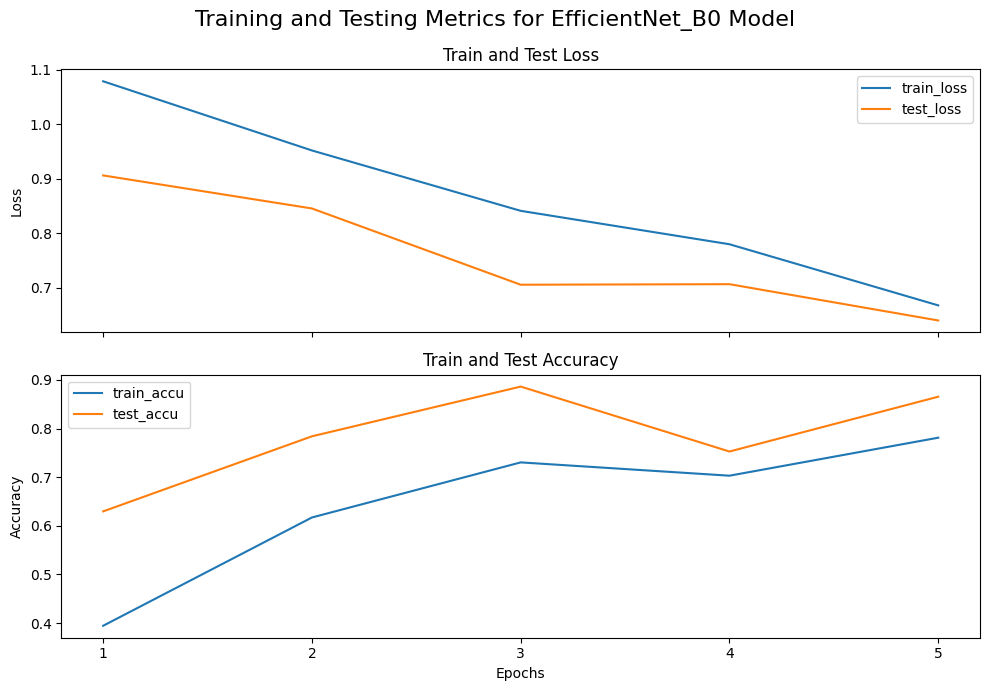

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))
fig, axis = plt.subplots(2, 1, sharex=True, figsize=(10, 7))

fig.suptitle("Training and Testing Metrics for EfficientNet_B0 Model", fontsize=16)
axis[0].plot(results["train_loss"], label="train_loss")
axis[0].plot(results["test_loss"], label="test_loss")
axis[0].set_title("Train and Test Loss")
axis[0].set_ylabel("Loss")
axis[0].legend()

axis[1].plot(results["train_accu"], label="train_accu")
axis[1].plot(results["test_accu"], label="test_accu")
axis[1].set_title("Train and Test Accuracy")
axis[1].set_ylabel("Accuracy")
axis[1].set_xlabel("Epochs")
axis[1].legend()

plt.xticks(ticks=range(len(results["train_loss"])), labels=range(1, len(results["train_loss"])+1))
plt.tight_layout()
plt.show()  

In [20]:
eva_result, conf_mat = evaluation.evaluation(model=model,
                                           test_data=test_dataloader,
                                           device=device)
# Import pandas for data manipulation
import pandas as pd
evaluation_df = pd.DataFrame(eva_result, index=["Correctness"])
print(f"The class name of data: {class_names}")
evaluation_df

              precision    recall  f1-score   support

           0       0.88      0.88      0.88        25
           1       0.72      0.95      0.82        19
           2       0.96      0.77      0.86        31

    accuracy                           0.85        75
   macro avg       0.85      0.87      0.85        75
weighted avg       0.87      0.85      0.85        75

The class name of data: ['pizza', 'steak', 'sushi']


,precision,Recall,f1_score
Correctness,85.33%,86.72%,85.18%


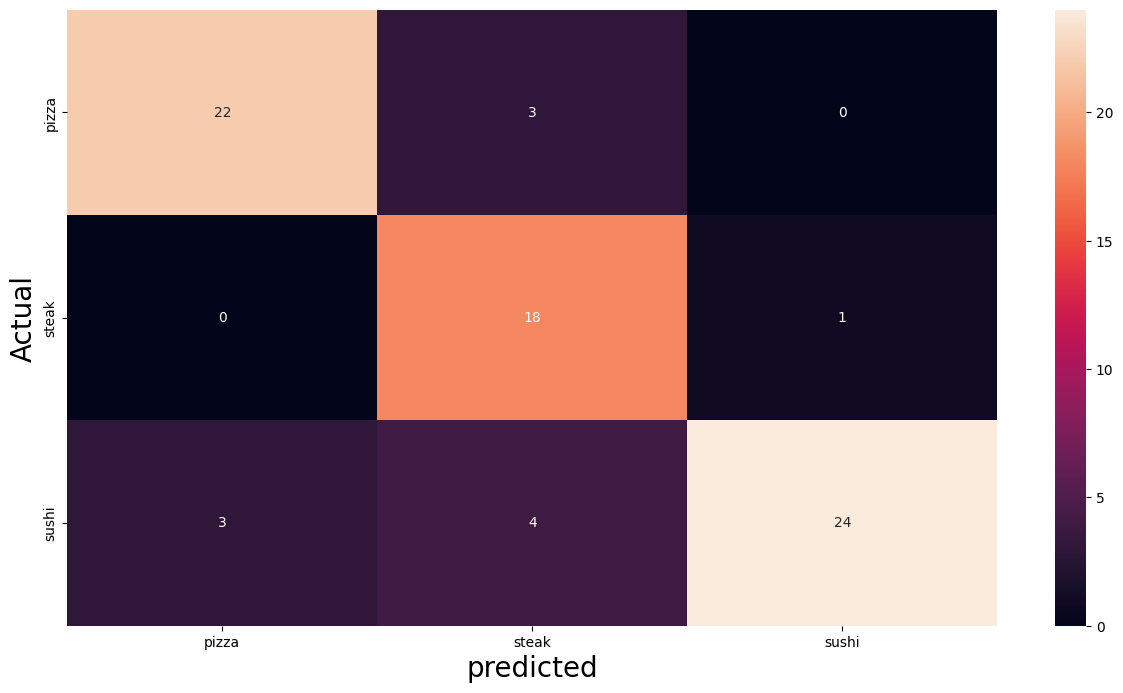

In [21]:
evaluation.plot_conf_metrics(confution_matr=conf_mat,
                             class_name=class_names)

The model is fine even there is some misclassification.
- The model is littel bit biased to steack class, becuase the predecit 3 pizza as steack and 4 sushi as steack so in total 7 times make mistake to predict other classes as steack. for other classes pizza in total 3(3 sushi as pizza), 1 sushi(1 steack as sushi). 



# save model

In [24]:

# setup save destination
model_dir = ROOT_DIR / "models"

utils.save_model(model=model,
                 target_dir=model_dir,
                 model_name="efficientnet_b0_transfer_learning.pth")

Saving the model to: /home/nigatie/Documents/ML_DL/02_Deep_Learning/models/efficientnet_b0_transfer_learning.pth
Model saved successfully!


# Load Model